# Explore sims
Hillas parameter distributions, image centroids, energies, multiplicities and reconstructed directions for a chosen
set of telescopes and cuts, from an already processed sim_telarray production (run `process_sims.ipynb` first). The
simulated counterpart of `analysis_tools/explore_events.ipynb`.

Everything is set in **Selection** below: pick a config, then override its telescopes or cuts there to compare
selections.

Camera coordinates are sim_telarray's, fixed to the alt-az mount: +x towards higher altitude, +y towards lower azimuth.

# Imports

In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from heap import diagnostics as dg
from heap import events as ev
from heap import process_simulation as ps
from heap.parameterize import TAB10_COLORS
from heap.reconstruction import reconstruct_directions
from run_simulation import load_config

# Selection

In [ ]:
CONFIG = Path("../configs/simulation.yaml") # relative to simulation_tools/; or a production's <output_dir>/slurm/<job>.yaml
cfg = load_config(CONFIG)

OUTPUT_DIR = cfg["paths"]["output_dir"]
NAME = cfg["production"]["name"]
TAG = cfg["sim_telarray"]["tag"]
SIMTEL_FILES = sorted(glob.glob(str(OUTPUT_DIR / "simtel" / TAG / f"{NAME}_run*.simtel.zst")))
PROCESSED_DIR = OUTPUT_DIR / "processed" / TAG

# override any of these, e.g. TELESCOPES = ["T1", "T2", "T3"] or IMAGE_CUTS = {"width": ("value", 0.3)}
TELESCOPES = None # None = every telescope; "T<sim_telarray id>"
MIN_TEL = 2
MIN_NPIX = 3
IMAGE_CUTS = {} # {column: (mode, threshold)}, see heap.events.apply_cut()

# plotting
N_EVENTS = 4 # reconstructed events to display
PLOT_RADIUS = 3 # deg from the camera center for the direction histogram
ENERGY_BINS = np.logspace(0, 3, 16) # TeV

In [ ]:
runs = ps.run_table(SIMTEL_FILES)
if TELESCOPES is None:
    TELESCOPES = [f"T{tel_id}" for tel_id in runs.iloc[0].tel_id]
COLORS = {name: TAB10_COLORS[i] for i, name in enumerate(sorted(TELESCOPES))}
print(f"{NAME} ({TAG}): {len(runs)} runs, {(runs.n_showers * runs.n_use).sum()} events simulated")
print(f"telescopes {TELESCOPES}, cuts: min_tel {MIN_TEL}, min_npix {MIN_NPIX}, image cuts {IMAGE_CUTS}")

# Events
Images of `TELESCOPES` matched into array events by `Run` and `EventID` (`heap.process_simulation.load_events()`),
then the cuts (`heap.events.apply_cuts()`).

In [ ]:
df, showers = ps.load_events(PROCESSED_DIR, NAME, runs, TELESCOPES)
array = ev.apply_cuts(df, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
triggered = showers[showers.Event.isin(df.Event)]
after_cuts = showers[showers.Event.isin(array.Event)]
print(f"{df.Event.nunique()} events ({len(df)} images) before cuts, {array.Event.nunique()} events ({len(array)} images) after")

1450 events (1719 images) before cuts, 218 events (487 images) after


In [ ]:
# events per telescope combination before cuts, and how many of them still have MIN_TEL+ images after cuts
combo = df.groupby("Event").Telescope.agg(lambda t: " + ".join(sorted(t)))
n_images = array.Event.value_counts()
kept = combo.index.isin(n_images[n_images >= MIN_TEL].index)
pd.DataFrame({"before cuts": combo.value_counts(), "after cuts": combo[kept].value_counts()}).fillna(0).astype(int)

,before cuts,after cuts
Telescope,,
T1,149,0
T1 + T2 + T3,11,11
T1 + T2 + T3 + T6 + T7,2,2
T1 + T2 + T3 + T7,2,2
T1 + T3,35,35
T1 + T3 + T6,2,2
T1 + T3 + T6 + T7,1,1
T1 + T6,24,24
T1 + T6 + T7,19,19


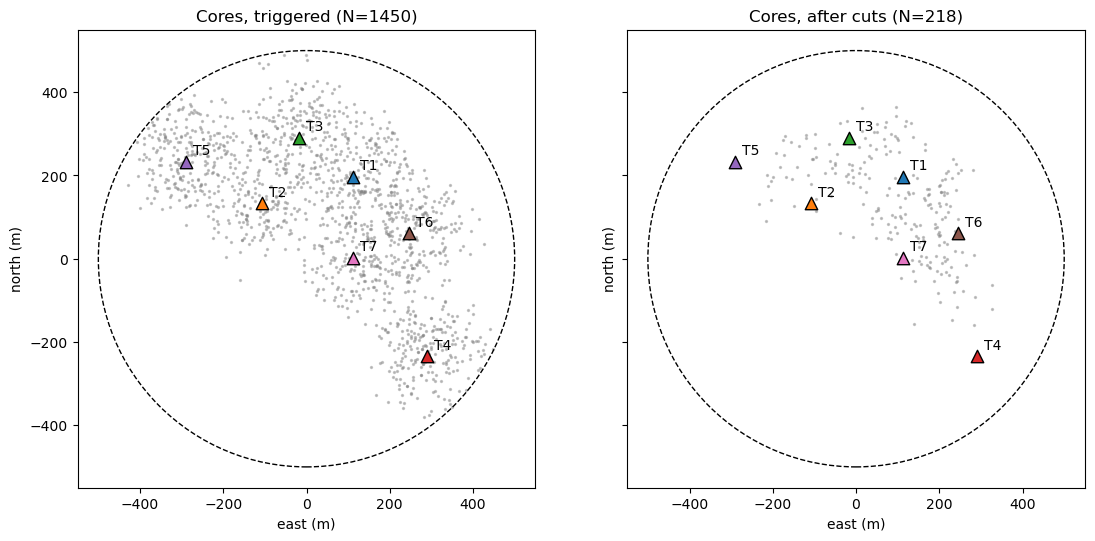

In [ ]:
ps.plot_cores(runs, {"triggered": triggered, "after cuts": after_cuts}, colors=COLORS)
plt.show()

# Energy and multiplicity
Energies of the simulated, triggered (any telescope of `TELESCOPES` with an image) and kept (after cuts) events, then
the number of telescopes per event. The simulated counts are the power law of `heap.read_simtel.read_run_header()`,
over every run.

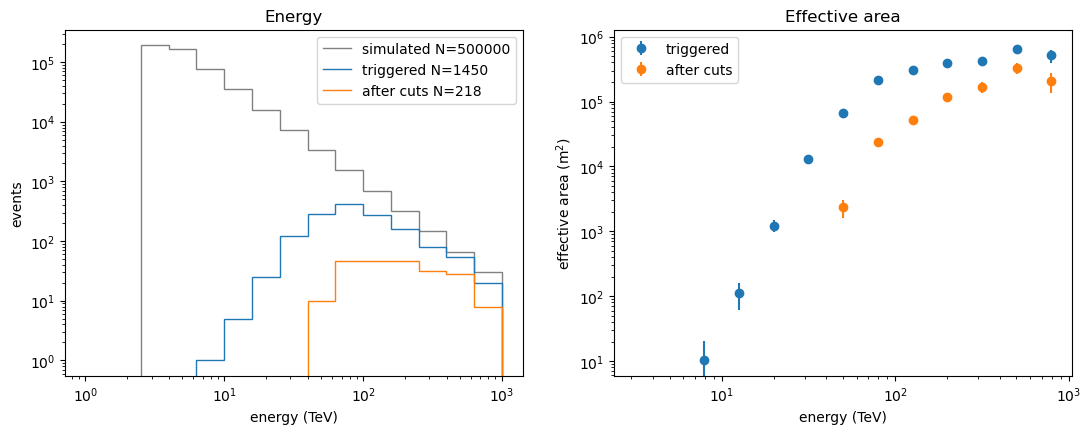

In [ ]:
ps.plot_energies(runs, {"triggered": triggered, "after cuts": after_cuts}, ENERGY_BINS)
plt.show()

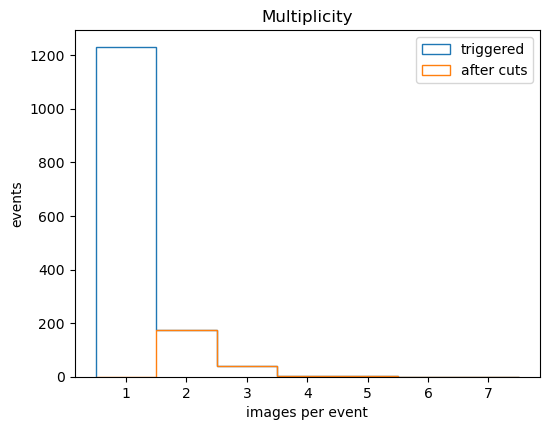

In [ ]:
ps.plot_multiplicity({"triggered": df, "after cuts": array}, len(TELESCOPES))
plt.show()

# Hillas parameters
One line per telescope, all telescopes pooled filled in grey. `distance` and `alpha` are from the camera center
(`process_simulation()`'s default `x`, `y`), the source position only without a wobble.

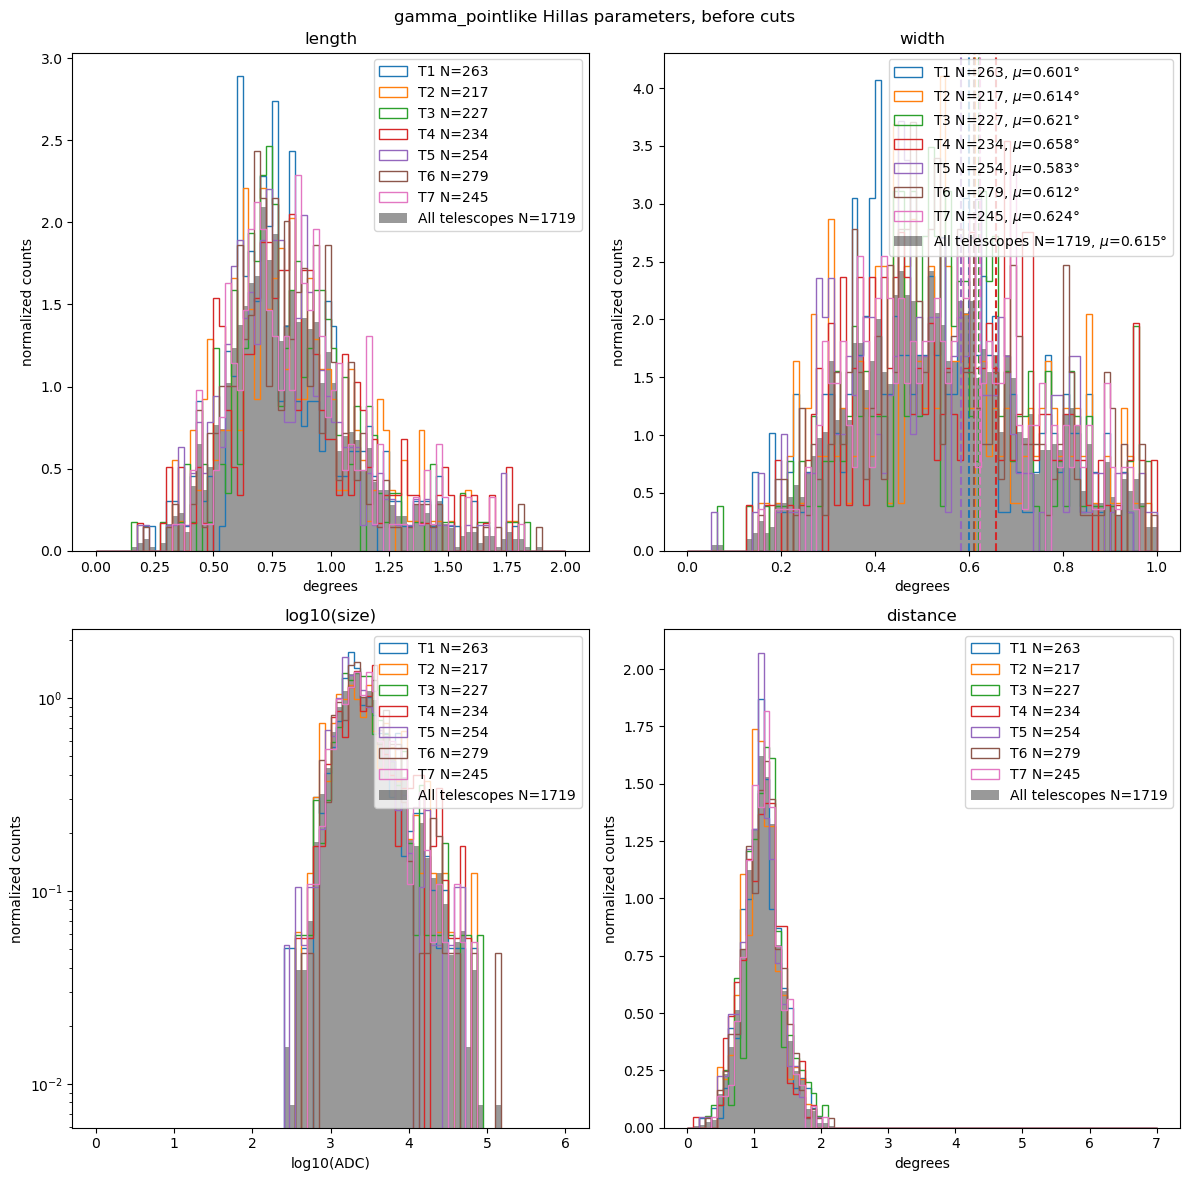

In [ ]:
ev.plot_hillas(df, f"{NAME} Hillas parameters, before cuts", colors=COLORS)
plt.show()

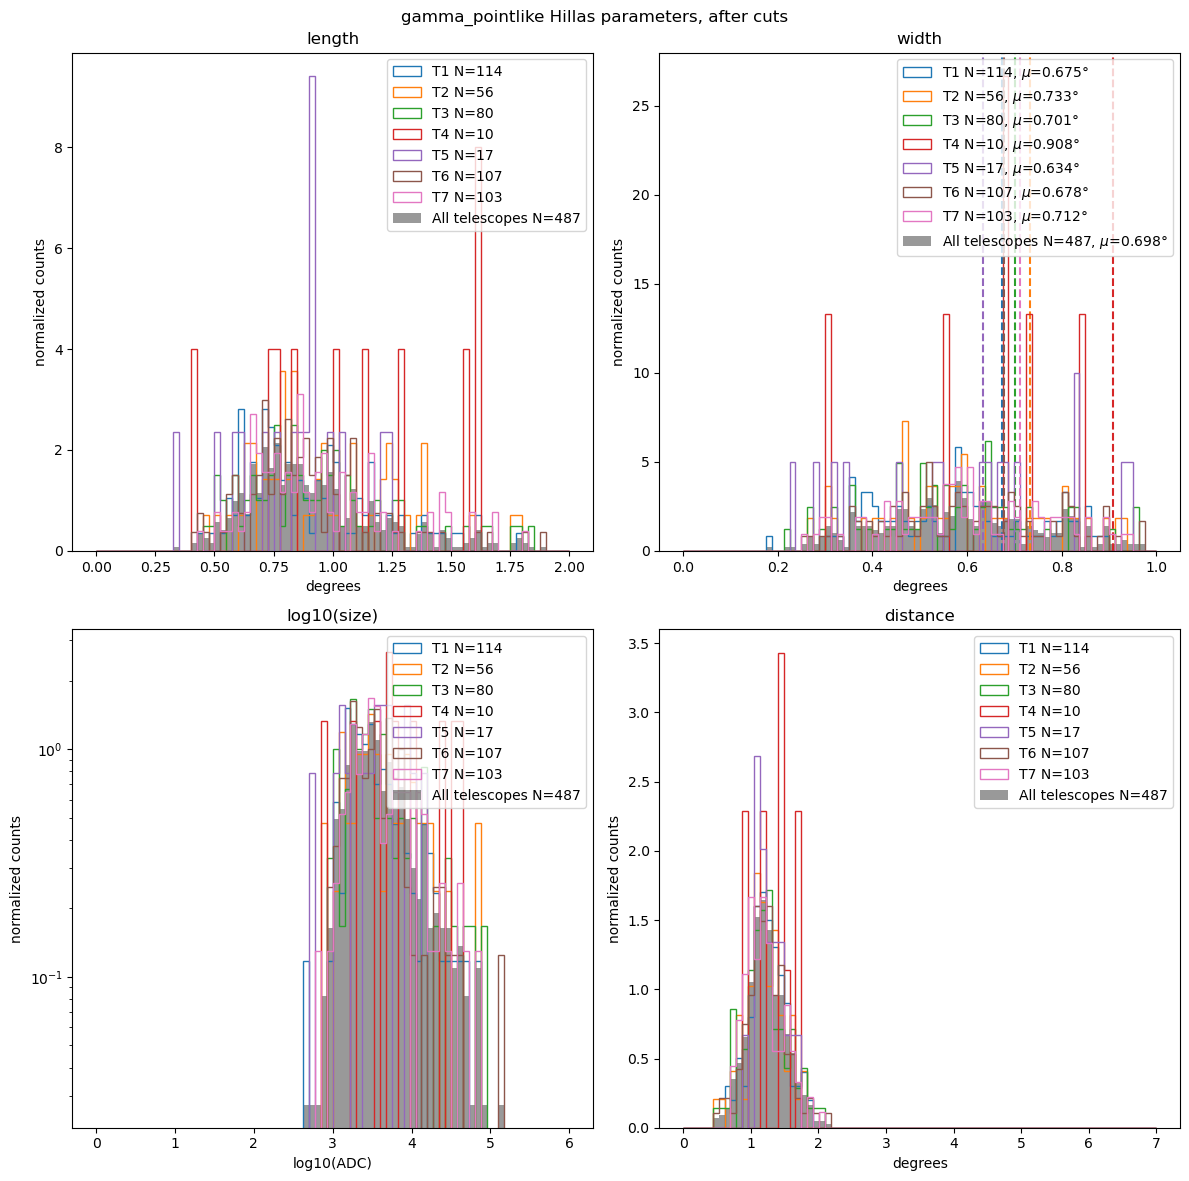

In [ ]:
ev.plot_hillas(array, f"{NAME} Hillas parameters, after cuts", colors=COLORS)
plt.show()

In [ ]:
array.groupby("Telescope")[["N_pix", "size", "length", "width", "distance", "alpha"]].describe().T

Telescope                 T1            T2            T3            T4  \
N_pix    count    114.000000     56.000000     80.000000     10.000000   
         mean      97.535088    116.910714    108.950000    182.800000   
         std      108.596287    132.271934    136.476075    169.942343   
         min       12.000000     16.000000     17.000000     14.000000   
         25%       37.250000     40.500000     38.500000     72.750000   
         50%       60.000000     67.000000     57.500000    101.500000   
         75%      108.250000    141.750000    111.000000    314.500000   
         max      655.000000    674.000000    742.000000    472.000000   
size     count    114.000000     56.000000     80.000000     10.000000   
         mean    6493.962399   8054.772158   7467.253625  12865.856178   
         std     9720.741657  12575.175376  12681.961395  13863.611807   
         min      448.109457    750.611592    935.836154    709.418198   
         25%     1917.289715   2207.285251   1882.815212   3860.363049   
         50%     2995.872260   3693.688216   3089.003627   5780.500050   
         75%     6527.648620   8161.375197   6248.141781  21493.516777   
         max    63258.028980  68298.760940  76996.386926  37741.846178   
length   count    114.000000     56.000000     80.000000     10.000000   
         mean       0.909249      0.963194      0.939319      1.098917   
         std        0.277461      0.303983      0.315801      0.419545   
         min        0.449734      0.464204      0.469798      0.406395   
         25%        0.709541      0.746488      0.726648      0.786673   
         50%        0.842741      0.868395      0.876953      1.072094   
         75%        1.071470      1.206482      1.056825      1.499181   
         max        1.797753      1.798441      1.836852      1.617371   
width    count    114.000000     56.000000     80.000000     10.000000   
         mean       0.674699      0.733111      0.701468      0.907752   
         std        0.295417      0.326876      0.331742      0.395733   
         min        0.178780      0.272699      0.215508      0.302861   
         25%        0.454886      0.515764      0.498097      0.683488   
         50%        0.602800      0.634026      0.635356      0.787642   
         75%        0.811953      0.896839      0.822176      1.293633   
         max        1.691519      1.738806      1.741865      1.467159   
distance count    114.000000     56.000000     80.000000     10.000000   
         mean       1.255120      1.208824      1.231160      1.349443   
         std        0.268462      0.283618      0.314862      0.294583   
         min        0.615201      0.499843      0.523915      0.900008   
         25%        1.107387      1.050769      1.047111      1.147615   
         50%        1.238330      1.199916      1.206335      1.430731   
         75%        1.421743      1.392919      1.444395      1.545752   
         max        1.897839      1.773438      2.025663      1.748723   
alpha    count    114.000000     56.000000     80.000000     10.000000   
         mean      31.096339     36.151292     31.239559     41.078478   
         std       23.648393     27.117588     25.082320     23.566511   
         min        0.361143      0.156518      0.146608     14.799781   
         25%       12.553693     11.511271      8.681003     18.464949   
         50%       24.654656     31.600854     28.256933     41.881854   
         75%       46.504741     57.228838     48.461170     55.573962   
         max       84.257931     84.155203     87.653124     85.676645   

Telescope                 T5             T6            T7  
N_pix    count     17.000000     107.000000    103.000000  
         mean      77.647059      93.093458    105.398058  
         std       55.044234     114.900329    113.704497  
         min        9.000000      18.000000     14.000000  
         25%       32.000000      39.500000     44.500000  
         50% 

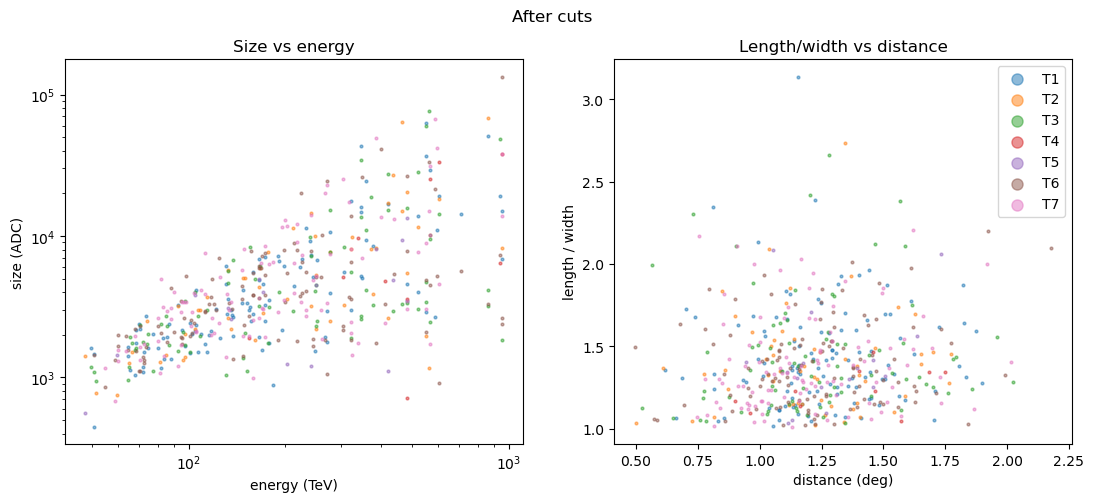

In [ ]:
ps.plot_image_params(array, showers, "After cuts", colors=COLORS)
plt.show()

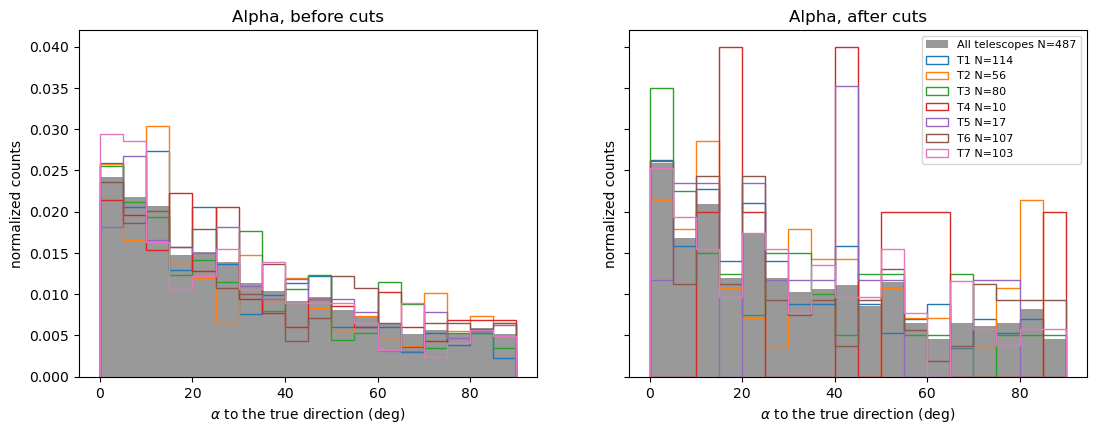

In [ ]:
# alpha to the true direction (the Hillas alpha is from the camera center)
ps.plot_alpha({"before cuts": df, "after cuts": array}, showers, colors=COLORS)
plt.show()

# Image centroids
Centroids (`x_c`, `y_c`) in camera coordinates, one bin per pixel.

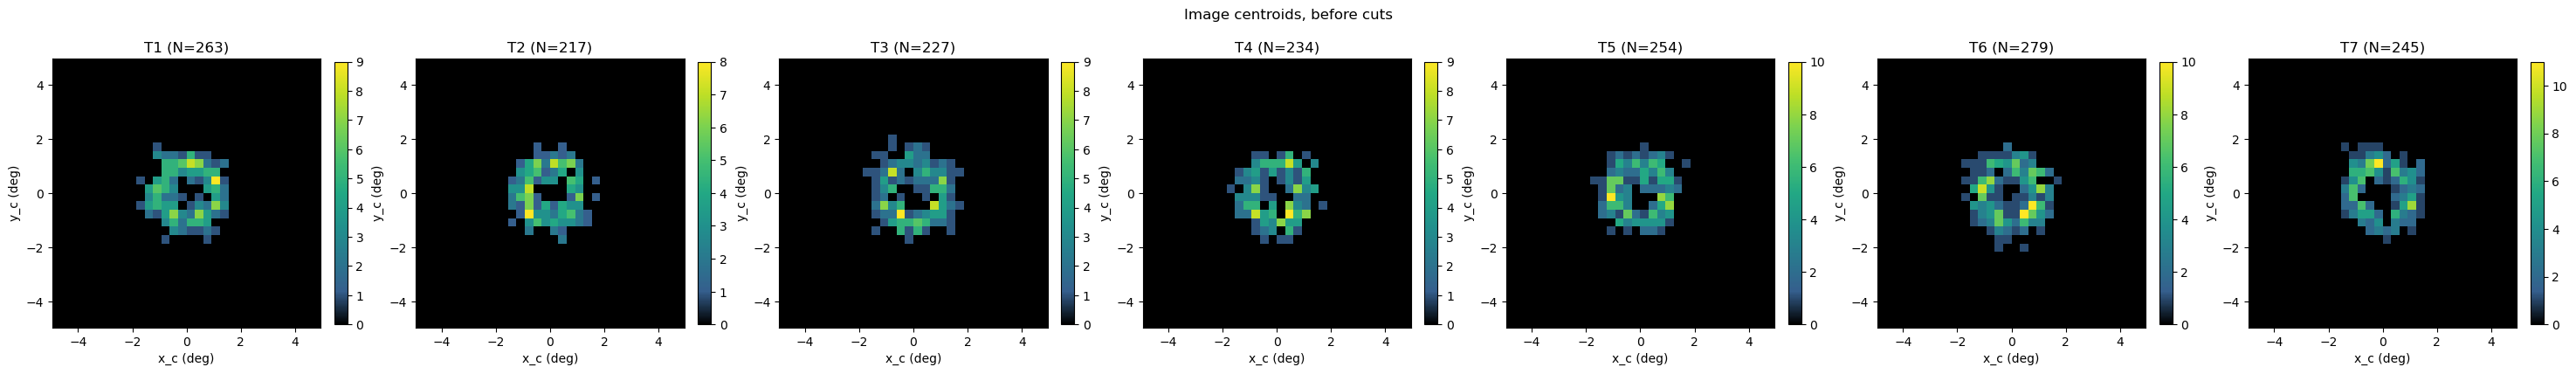

In [ ]:
dg.plot_centroids(df, "Image centroids, before cuts", telescopes=TELESCOPES)
plt.show()

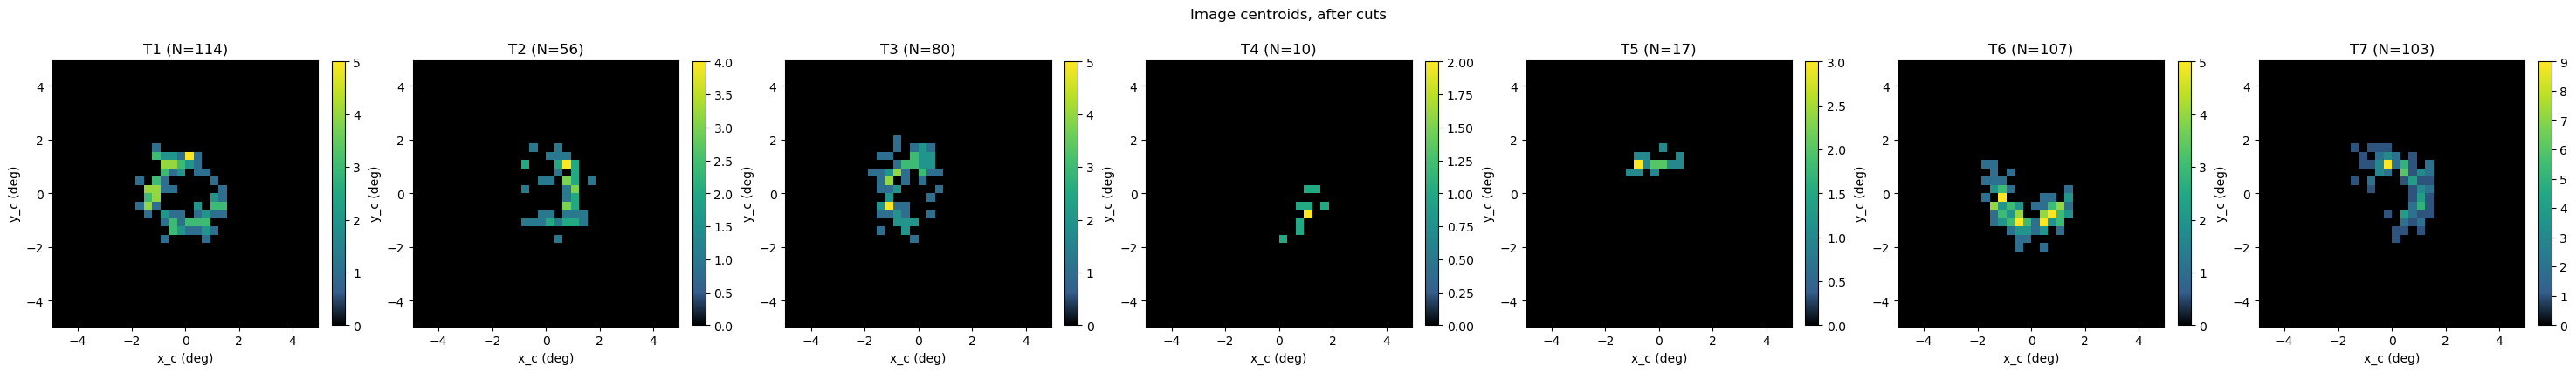

In [ ]:
dg.plot_centroids(array, "Image centroids, after cuts", telescopes=TELESCOPES)
plt.show()

# Reconstruction
Arrival directions (`heap.reconstruction`) against the primary's true direction (`true_x`, `true_y`, see
`heap.process_simulation.camera_position()`).

In [ ]:
directions = reconstruct_directions(array).merge(showers[["Event", "energy", "true_x", "true_y"]], on="Event")
directions["theta2"] = (directions.Xoffset - directions.true_x)**2 + (directions.Yoffset - directions.true_y)**2
print(f"{len(directions)} reconstructed events, 68% containment {np.sqrt(directions.theta2.quantile(0.68)):.3f} deg")

218 reconstructed events, 68% containment 1.691 deg


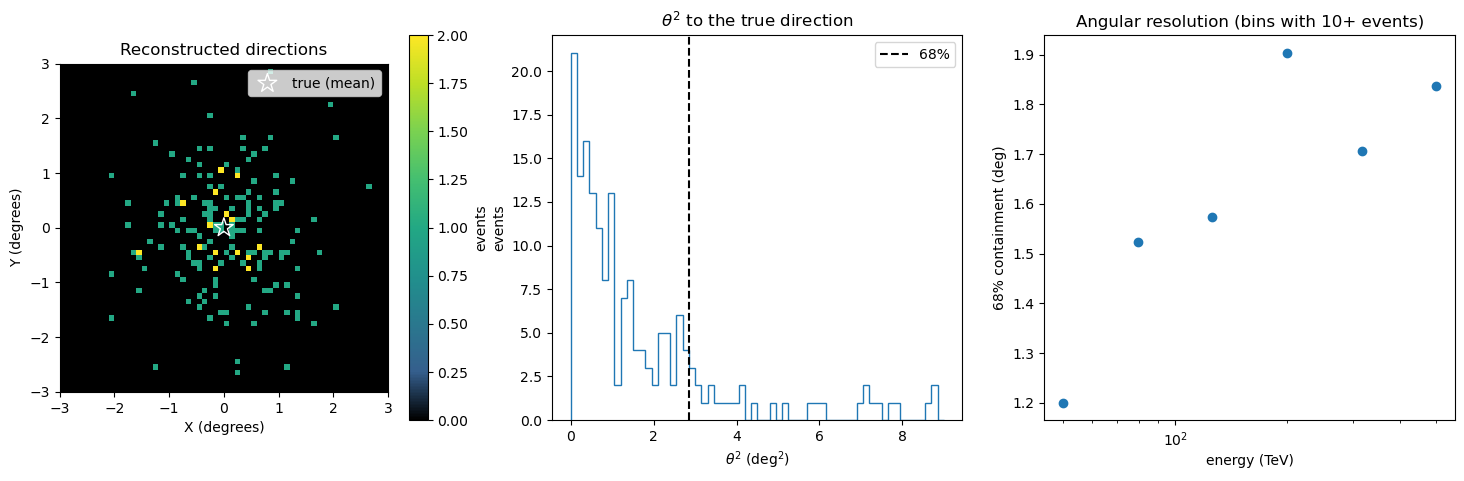

In [ ]:
ps.plot_directions(directions, ENERGY_BINS, radius=PLOT_RADIUS)
plt.show()

## Event display
Each cleaned image of an event, then all its Hillas ellipses together, with the reconstructed (x) and true (star)
directions. Run the cell again for other events.

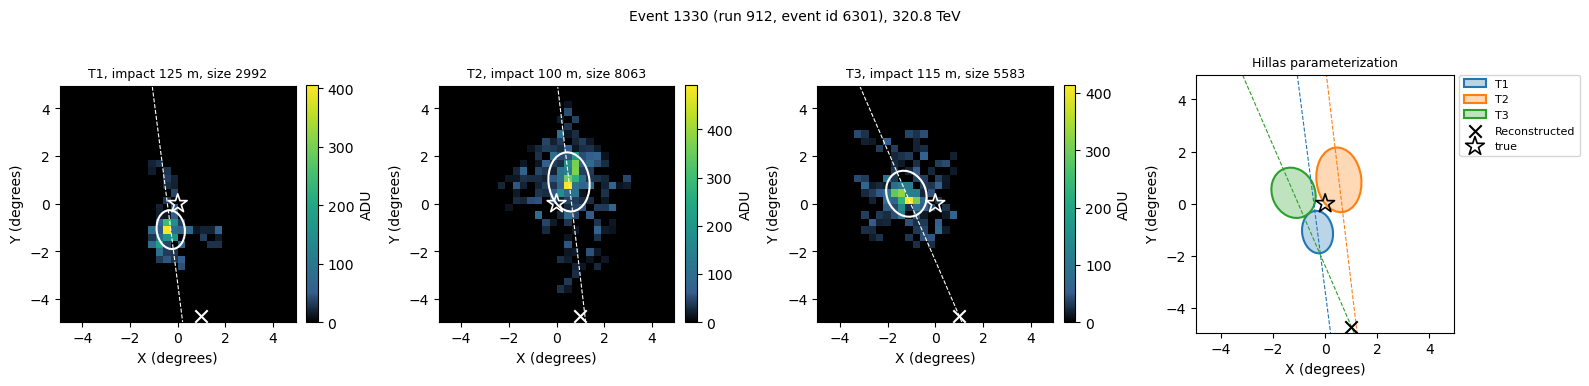

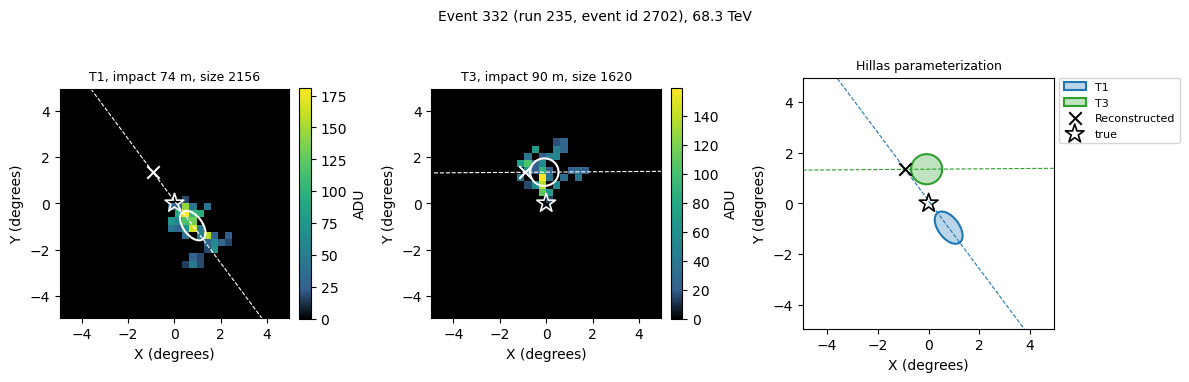

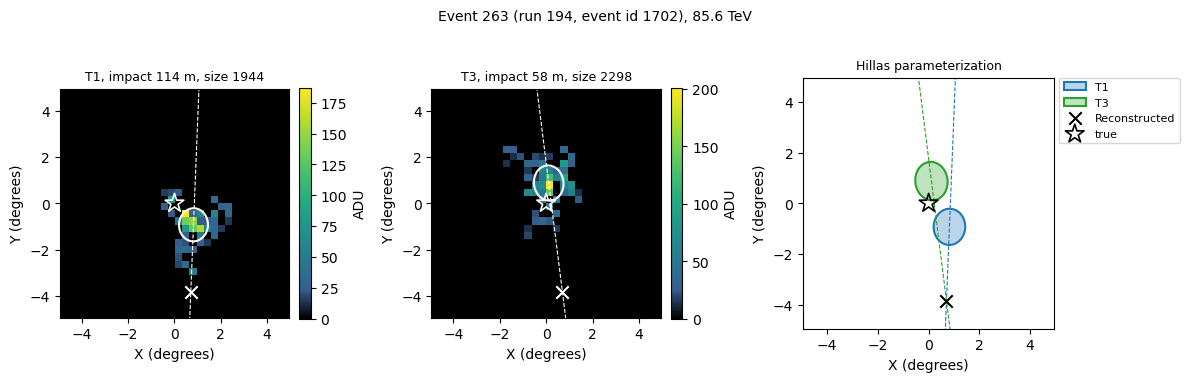

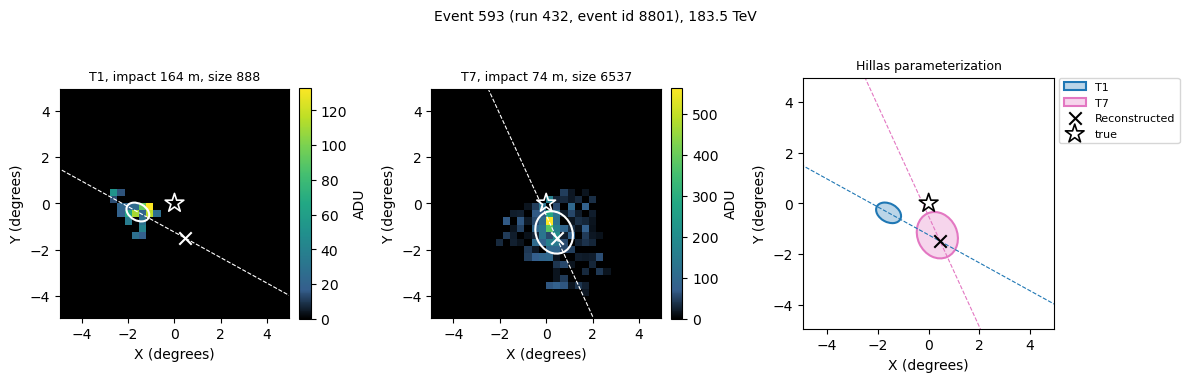

In [ ]:
for e in np.random.default_rng().choice(directions.Event, size=min(N_EVENTS, len(directions)), replace=False):
    ps.plot_event(
        array[array.Event == e], directions[directions.Event == e].iloc[0], showers.set_index("Event").loc[e],
        PROCESSED_DIR, NAME, colors=COLORS,
    )
    plt.show()